Boosting improves learning by correcting previous mistakes. Unlike Random Forest

Random Forest

Trees work independently.

Boosting

Trees work sequentially.

Each tree learns from previous errors.

| Feature                       | SHAP                      | LIME           |
| ----------------------------- | ------------------------- | -------------- |
| Full model explanation        | ✅                         | ❌              |
| Single prediction explanation | ✅                         | ✅              |
| Local explanation             | ✅                         | ✅              |
| Global feature importance     | ✅                         | ❌              |
| Model-specific optimization   | Excellent for tree models | Model-agnostic |
| Speed                         | Slower                    | Faster         |


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Teen_Mental_Health_Dataset.csv")

In [ ]:
label = LabelEncoder()

df["gender"] = label.fit_transform(df["gender"])

df["platform_usage"] = label.fit_transform(df["platform_usage"])

df["social_interaction_level"] = label.fit_transform(df["social_interaction_level"])

In [ ]:
X = df.drop("depression_label", axis=1)

y = df["depression_label"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y

)

In [ ]:
model = XGBClassifier(

    n_estimators=100,

    learning_rate=0.1,

    max_depth=4,

    random_state=42,

    eval_metric="logloss"

)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
prediction = model.predict(X_test)

In [ ]:
print("Accuracy")

print(accuracy_score(y_test,prediction))
print(classification_report(y_test,prediction))
print(confusion_matrix(y_test,prediction))

Accuracy
1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       1.00      1.00      1.00         6

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240

[[234   0]
 [  0   6]]


                     Feature  Importance
10             anxiety_level    0.311218
9               stress_level    0.288493
4                sleep_hours    0.205064
2   daily_social_media_hours    0.169604
1                     gender    0.005442
6       academic_performance    0.005185
0                        age    0.004945
11           addiction_level    0.004272
5   screen_time_before_sleep    0.003022
7          physical_activity    0.002754
3             platform_usage    0.000000
8   social_interaction_level    0.000000


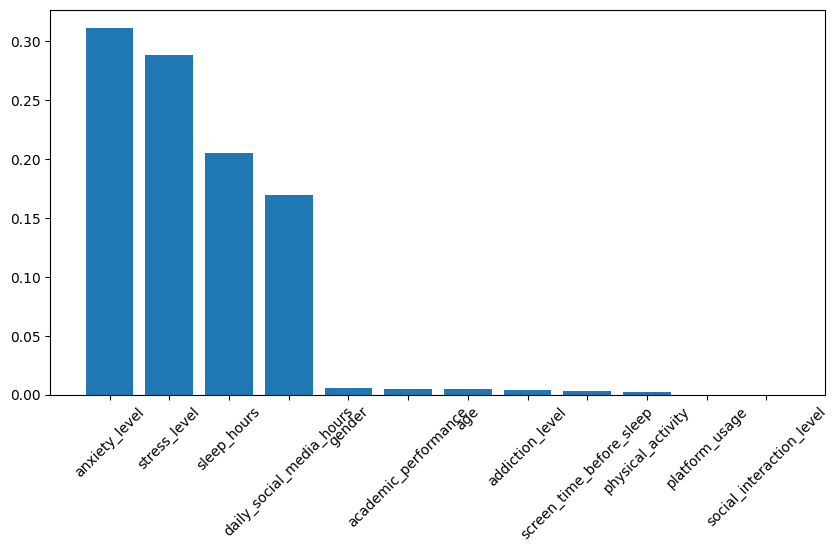

In [ ]:
importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":model.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

print(importance)
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(

    importance["Feature"],

    importance["Importance"]

)

plt.xticks(rotation=45)

plt.show()

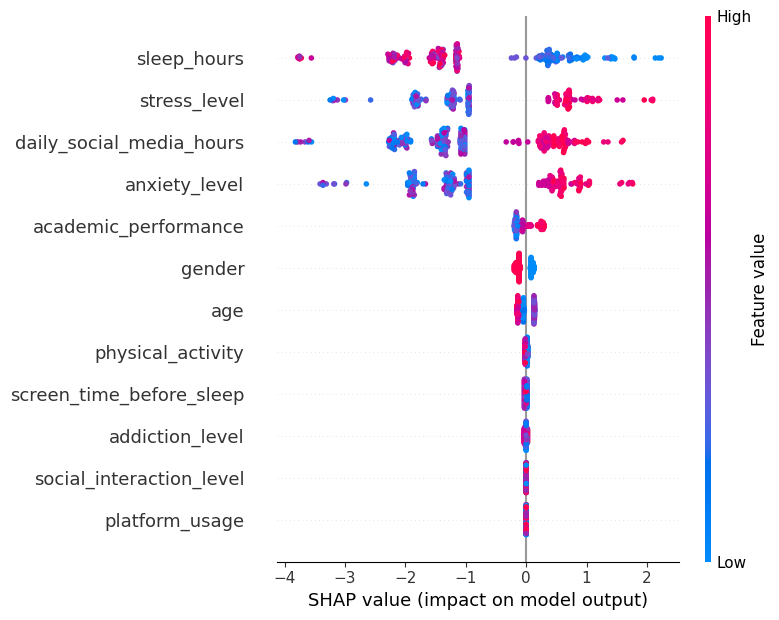

In [ ]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

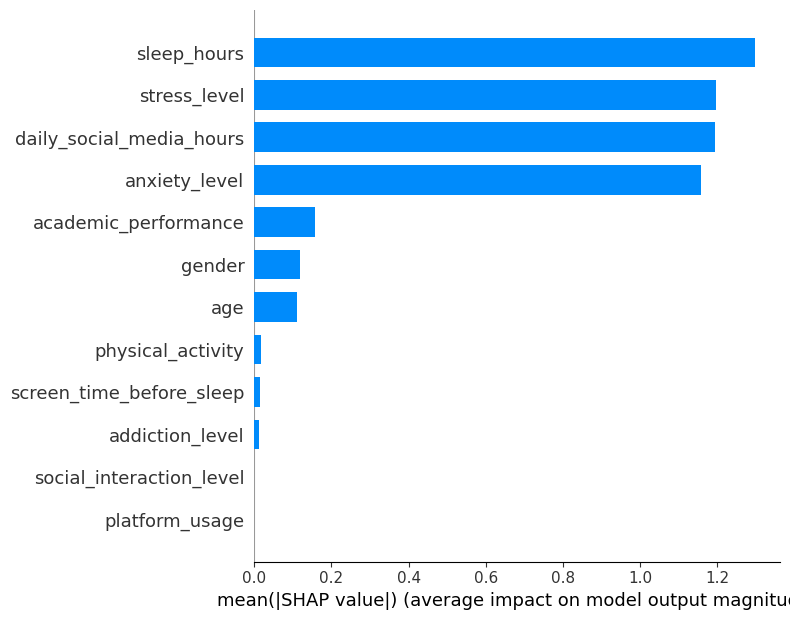

In [ ]:
shap.summary_plot(

    shap_values,

    X_test,

    plot_type="bar"

)

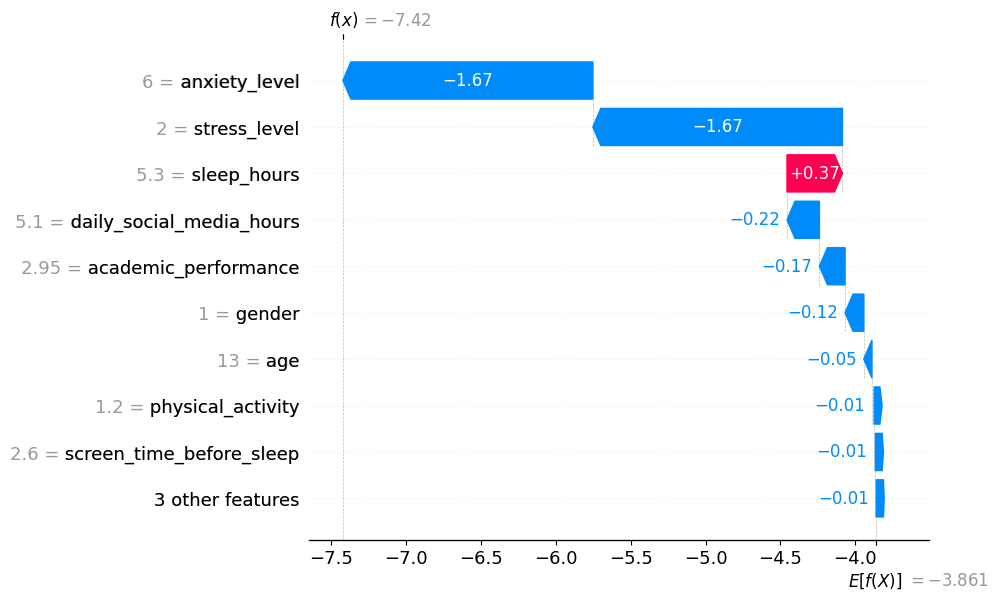

In [ ]:
student = X_test.iloc[[0]]
shap_values_student = explainer(student)
shap.plots.waterfall(

    shap_values_student[0]

)

In [ ]:
from lime.lime_tabular import LimeTabularExplainer
explainer = LimeTabularExplainer(

    training_data=X_train.values,

    feature_names=X.columns,

    class_names=["No Depression","Depression"],

    mode="classification"

)
exp = explainer.explain_instance(

    X_test.iloc[0],

    model.predict_proba,

    num_features=8

)
exp.show_in_notebook(show_table=True)
print(exp.as_list())

/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

[('3.00 < anxiety_level <= 6.00', -0.027048368333717963), ('stress_level <= 3.00', -0.0266010773743188), ('4.60 < daily_social_media_hours <= 6.40', 0.02126936964793309), ('screen_time_before_sleep > 2.40', 0.00975229219756862), ('2.51 < academic_performance <= 2.99', 0.006168667247178836), ('1.00 < platform_usage <= 2.00', 0.003965372854223279), ('0.00 < gender <= 1.00', -0.003674063693148868), ('age <= 14.00', -0.003662981947523829)]


In [ ]:
%%writefile app.py

import streamlit as st

st.title("Teen Mental Health Predictor")

age = st.slider("Age",10,20)

stress = st.slider("Stress Level",1,10)

sleep = st.slider("Sleep Hours",1,10)

if st.button("Predict"):
    if stress>7 or sleep<5:
        st.success("High Risk")
    else:
        st.success("Low Risk")

Overwriting app.py


In [ ]:
!pip install pyngrok -q

from pyngrok import ngrok

ngrok.set_auth_token("3HXBU3A37tfGUcxZqjIzd4krTYe_6CvaK72gTqm1mbqm2GE6i")

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8502)
print(public_url)

NgrokTunnel: "https://spearhead-landing-prissy.ngrok-free.dev" -> "http://localhost:8502"
